# BTD6 Banana Farms. Does the efficiency metric predict which farm earns the most
[Bloons Tower Defense 6](https://www.bloonswiki.com/Bloons_TD_6) (BTD6 or also abbreviated as Bloons TD 6) is the 6th game in the Bloons Tower Defense series created by Ninja Kiwi. It goes back all the way to 2007 when the first BTD game has been released. The first BTD installments were very popular flash games so it's a well known series.

The objective is as simple as: you place down monkeys (towers), they pop the balloons (called bloons in the game) that go along the track, earn cash from it, and you use that cash to further upgrade your defense

But there's the key. In order to **upgrade your defense**, you need to **earn cash**. This process naturally occurs since you get *end-of-round cash* and cash for each bloon you pop.<br>
*But what if we could **control** this process*. And we could! Because the game (in fact, the previous 2 games too) has a tower called a "Banana Farm".

**So is it worth it to reinvest the cash we earn into banana farms so we can make more cash?**

This is what we're going to find out today!<br>
But first

### Scope
The farming in BTD6, funnily enough, is extremely complicated and thorough!
- You have other towers that have upgrades that earn cash
- You have entire strategies, combination of towers, sequences of which farms to use, synergies
- There are deposits, abilities, buffs
- An in-game map has a limited number of places where a tower can be placed which impacts farming quite a lot
- There are also towers that have nothing to do with farming but tremendously help the actual farming towers!

If interested, you can read more regarding it [here](https://bloons.fandom.com/wiki/Income_Farming_(BTD6)) 

So with that being said.. We need to define a scope<br>
In this project we'll analyse only **the base banana farm tower** with **no** strategies, relationships, synergies or abilities.

We'll analyse some key banana farm instances, the main 3 paths, their crosspaths and answer the question:
<h3 align="center"><em>How well does a farm’s efficiency predict its net worth after N rounds when its income is reinvested, and under which conditions does the prediction fail?</em></h3>

But perhaps, first we need to clarify some things about how this game works..

## Brief Introduction
- To place a tower it costs in-game cash, the banana farm is a particularly expensive one compared to the other towers (earning the cash before a farm is outside the scope)
- Once a tower is placed, you can invest more cash into it by buying an upgrade
- You can choose between 3 **paths** to upgrade (it looks like this):

    ![banana_farm.png](./media/images/1_banana_farm_paths.png)

    - The upgrades are also called **tiers**
    - There are a maximum of 5 tiers per path but you can't have the same tier 5 twice per path for a tower
    - You can upgrade only 2 paths at once but only one can go past tier 2 (notice how the higher tiers of the other 2 paths have lower opacity):

    ![tier_3.png](./media/images/2_banana_farm_tier_3.png)

    - So in this example, whichever tier you decide to upgrade next out of the remaining paths, the other one gets locked:

    ![crosspath_1.png](./media/images/3_banana_farm_crosspath_1.png) ![crosspath_2.png](./media/images/4_banana_farm_crosspath_2.png)

    - This is called **crosspathing** and the path other than your main one is called a **crosspath**
    - The notation of identifying a tower is such:<br> <h5 aling="center"><strong>[Top Path Tiers]-[Middle Path Tiers]-[Bottom Path Tiers]</strong></h5> where the tiers are numbers. So for the images I've shown, the notation looks like this:<br><br>
    0-0-0<br>3-0-0<br>3-1-0; 3-0-2<br><br>
    This notation will be used throughout the project to identify each farm specification 

- Each path is vastly different, it has a different specialized function along with its strengths and weaknesses
- In the game you have rounds which bloons come out and you need to defend them, but during each round the farms generate cash
- Most farms generate the same amount of cash every round 

This is all we need before we begin. First I want to note that for this project we'll be using the **Medium** difficulty costs of the towers (there are 4 difficulties that change the cost of the towers by a percentage) and also we will assume that we have full **Monkey Knowledge** - this is an in-game skill-tree (somewhat) that gives you permanent upgrades such as increased farm sellback or more cash production etc. I'm counting this too because it's rather easy to get, most players have it and so we can properly estimate the efficiency of the farms when we assume that we have all the extra buffs that can give some tiers an edge to others. All simulations are done between rounds (not during them as this is out of scope).

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from src.loader import load_specs
from src.simulation import calculate_efficiency, payback_period, bank_efficiency, simulate, compare, best_stop_round, rank_agreement, leader_changes

In [ ]:
DATA_PATH = Path("data") / "farms.csv"
START_CASH = 26_000          # Just above the price of the most expensive build (4-2-0)
N_ROUNDS = 60                # How many rounds every simulation runs
SLOT_CAPS = [None, 20, 10, 5]  # None = unlimited farm slots

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

Let's quickly go over the 3 banana farm paths.

- The top path focuses purely on increasing the income making. The tier 4 and 5 produce large crates of bananas and produce much more a round but with the compromise of their expensive price

- The middle path is a bank. It collects money each round and gains 15% interest on the cash it has in its balance. The player needs to manually collect the balance (it doesn't automatically go to your total cash like the other upgrades). The tier 4 adds an ability and a deposit, where the deposited money gains 15% interest after 2 rounds but this is out of scope. The balance has a fixed capacity

- The bottom path is considered the convenient option. Usually you need to hover your cursor over the bananas to collect them (or manually collect your balance) but with the bottom path it automatically collects bananas. But its advantage is also that it has increased sellback which finds potential in strategies that are out of scope. This is considered the most beginner-friendly and lazy farming path

So if we look at it from another perspective: the top path maximizes production, the middle path requires more math and effort, and the bottom path maximizes convenience while still making an acceptable amount of cash. Intuitively this would tell us that the middle path should reward more since it requires more thought and that perhaps the top path is a good late-game option. 

Let's keep this in mind as we go in depth.

## Collecting The Banks
As we know banks passively gain income, they gain interest for the income in their balance and have a capacity. So here we need to find out how to maximize the income we could get. We can do this by simulating collecting from a bank each N rounds (every 1 round, 2, 3, ..., etc) until we find the interval that's the best. Unfortunately for the higher tier bank, the mechanic that makes it compete is outside the scope, and considering that the base income gain is the same, naturally its efficiency falls off due to its higher price.

It's also important to note now that the maximum capacity of a tier 3 bank is 9500, for tier 4 - 12500.

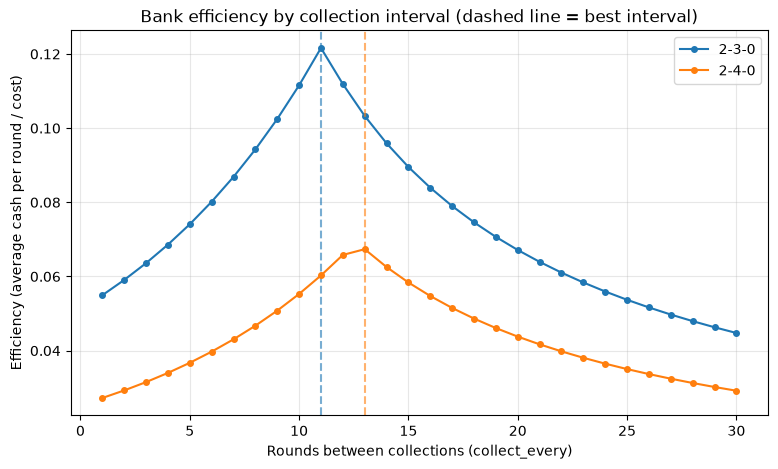

Best collection interval: {'2-3-0': 11, '2-4-0': 13}


In [3]:
base_specs = load_specs(DATA_PATH, collect_every=1)

banks = [spec for spec in base_specs if spec.is_bank]
MAX_INTERVAL = 30
intervals = np.arange(1, MAX_INTERVAL + 1)

best_interval = {}
fig, ax = plt.subplots()
for bank in banks:
    curve = bank_efficiency(bank, MAX_INTERVAL)
    best_interval[bank.tier_name] = int(curve.argmax()) + 1
    line, = ax.plot(intervals, curve, marker="o", markersize=4, label=bank.tier_name)
    ax.axvline(best_interval[bank.tier_name], color=line.get_color(), linestyle="--", alpha=0.6)

ax.set_xlabel("Rounds between collections (collect_every)")
ax.set_ylabel("Efficiency (average cash per round / cost)")
ax.set_title("Bank efficiency by collection interval (dashed line = best interval)")
ax.legend()
plt.show()

print("Best collection interval:", best_interval)

So judging by the results of the plot, it's most efficient to collect from the banks every 11 rounds for the tier 3 and every 13 rounds for the tier 4. The efficiency after the peak drops down since the capacity will have been reached and we will not be collecting the cash, so we're losing lots of money.

Now let's go over the math behind the best collection interval

Let $P$ be the cash the bank generates per round, $r=0.15$ the interest rate, $C$ the capacity and $q=1+r$. If we do not collect, the balance after round $n$ is

$$B_n=\min\bigl(C,\,(B_{n-1}+P)\,q\bigr),\qquad B_0=0 .$$

Without the cap this is a geometric series, $B_n=P\sum_{j=1}^{n}q^{\,j}$, so

$$B_n=P\,q\,\frac{q^{\,n}-1}{r}.$$

Collecting every $k$ rounds pays $B_k$ once, so the average cash per round is $A(k)=\frac{B_k}{k}$ and the efficiency is $\varepsilon(k)=\frac{A(k)}{\text{cost}}$.

**Before** the cap, waiting always helps. Treat $k$ as a real number and let $f(k)=\dfrac{q^{k}-1}{k}$. Then

$$f'(k)=\frac{g(k)}{k^{2}},\qquad g(k)=k\,q^{k}\ln q-q^{k}+1 .$$

Since $g(0)=0$ and $g'(k)=k\,q^{k}(\ln q)^{2}>0$ for $k>0$, we get $g(k)>0$, so $f'(k)>0$ and $A(k)$ is increasing.

**After** the cap, waiting always hurts. The balance is stuck at $C$, so $A(k)=\frac{C}{k}$, which is decreasing.

The maximum is therefore where the uncapped balance first reaches $C$. Solving $B_k=C$ gives

$$k^{*}=\frac{\ln\!\Bigl(1+\dfrac{rC}{Pq}\Bigr)}{\ln q}.$$

The best integer interval is $\lfloor k^{*}\rfloor$ or $\lceil k^{*}\rceil$, whichever gives the larger $A(k)$.

| Bank | $C$ | $k^*$ | $A(\lfloor k^*\rfloor)$ | $A(\lceil k^*\rceil)$ | Best |
|---|---|---|---|---|---|
| 2-3-0 | 9500 | 11.02 | 860.4 | 791.7 | 11 |
| 2-4-0 | 12500 | 12.61 | 939.4 | 961.5 | 13 |

This matches the dashed lines in the plot.

## Efficiency of Each Farm
So since we know the best collect interval for the banks, we will use this when comparing the efficiency of the other farms.

In [4]:
# Loads the final specs and gives every build a fixed colour
specs = load_specs(DATA_PATH, collect_every=best_interval)
names = [s.tier_name for s in specs]
colors = {name: plt.cm.tab10(i) for i, name in enumerate(names)}

But what exactly is this "efficiency" I constantly keep referring to? It's simply the cash a farm produces a round divided by its total cost (all upgrades and base price of the farm). A more efficient farm will pay back the cash you invested for it sooner than a less efficient one. Efficiency in this project will be defined as $ \varepsilon $

Let's see the farms I chose but especially pay attention to their total cost and their income per round:

In [5]:
pd.DataFrame({
    "tier_name": [s.tier_name for s in base_specs],
    "cost": [s.cost for s in base_specs],
    "income_per_round": [s.income for s in base_specs],
    "is_bank": [s.is_bank for s in base_specs],
    "sell_rate": [s.sell_rate for s in base_specs], # The bottom crosspath X-X-2 (and above for tier 3+) has increased sell rate
})

,tier_name,cost,income_per_round,is_bank,sell_rate
0,1-0-0,1725.0,120.0,False,0.77
1,2-0-0,2325.0,160.0,False,0.77
2,2-2-0,3425.0,208.0,False,0.77
3,2-0-3,5675.0,400.0,False,0.87
4,0-2-3,5675.0,416.0,False,0.87
5,2-0-4,20675.0,1400.0,False,0.87
6,2-0-2,2975.0,160.0,False,0.87
7,4-2-0,25425.0,1950.0,False,0.77
8,2-3-0,7075.0,338.0,True,0.77
9,2-4-0,14275.0,338.0,True,0.77


The farms I chose are pretty random but not entirely pointless too. You have interesting comparisons such as the 1-0-0 and 2-0-0: is it better to spend extra cash to produce even more bananas or should you stick with the first upgrade. Another fascinating one is the bottom path crosspaths: 2-0-3 and 0-2-3, the conflict here is whether producing more bananas is better or producing less bananas that have higher value each or even another - is it better to go for 2-2-0 (more production with bananas that give more cash) or to ignore that upgrade. Unfortunately, as interesting as this is to ramble about, it's outside the scope, here we are focusing on efficiency, net worth and reinvesting

Well let's calculate the efficiency for each one and in how many rounds they pay back their cost and visualize it:

In [6]:
efficiency_table = pd.DataFrame({
    "tier_name": names,
    "cost": [s.cost for s in specs],
    "efficiency": [calculate_efficiency(s) for s in specs],
    "payback_rounds": [payback_period(s) for s in specs],
    "sell_rate": [s.sell_rate for s in specs],
}).sort_values("efficiency", ascending=False).reset_index(drop=True)

efficiency_table.round(4)

,tier_name,cost,efficiency,payback_rounds,sell_rate
0,2-3-0,7075.0,0.1216,8.2228,0.77
1,4-2-0,25425.0,0.0767,13.0385,0.77
2,0-2-3,5675.0,0.0733,13.6418,0.87
3,2-0-3,5675.0,0.0705,14.1875,0.87
4,1-0-0,1725.0,0.0696,14.3750,0.77
5,2-0-0,2325.0,0.0688,14.5312,0.77
6,2-0-4,20675.0,0.0677,14.7679,0.87
7,2-4-0,14275.0,0.0674,14.8460,0.77
8,2-2-0,3425.0,0.0607,16.4663,0.77
9,2-0-2,2975.0,0.0538,18.5938,0.87


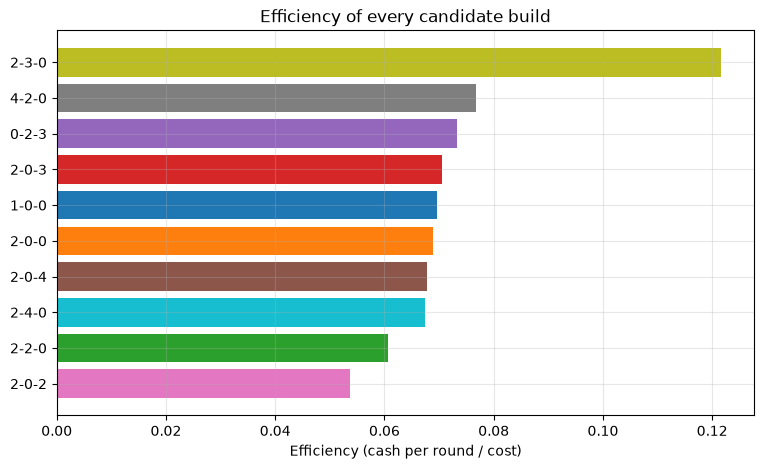

In [7]:
fig, ax = plt.subplots()
ax.barh(efficiency_table["tier_name"], efficiency_table["efficiency"],
        color=[colors[n] for n in efficiency_table["tier_name"]])
ax.invert_yaxis()   # the most efficient build on top
ax.set_xlabel("Efficiency (cash per round / cost)")
ax.set_title("Efficiency of every candidate build")
plt.show()

This is quite interesting (and in fact, it surprised even me). Here the bank absolutely dominates. This is because it is in fact incredibly efficient. We have to keep in mind that specifically the 4-2-0 farm is a very pricey tower so, it being that efficient is pretty good. We also notice tier 4 bottom path upgrades being less efficient than much cheaper options.

Now in dead last place we have 2-0-2 which is the same as 2-0-0. The bottom crosspath increases the sellback so in theory it should be even more efficient, right? But we are talking about producing cash, we are not considering the cash we'll get from selling the farms. Which means that the money we invested for this crosspath is pretty much wasted regarding its efficiency - but the value is found when we consider selling it back which is outside the scope.

But what efficiency ignores is the **sell value**.

If we hold a farm for $h$ rounds and then sell it at sell rate $s$, the net gain per dollar spent is

$$R(h)=\frac{h\cdot\text{income}-(1-s)\,\text{cost}}{\text{cost}}=\varepsilon\,h-(1-s).$$

This is a straight line: $\varepsilon$ is the slope and $-(1-s)$ is the starting point. The farm recovers its resale loss after $h_0=\dfrac{1-s}{\varepsilon}$ rounds: about 2.4 rounds for 2-0-2 ($s=0.87$) against 3.3 for 2-0-0 ($s=0.77$). The two lines cross at

$$h^{*}=\frac{(1-s_A)-(1-s_B)}{\varepsilon_A-\varepsilon_B}\approx 6.7 \text{ rounds},$$

so if we hold a farm for fewer than about 7 rounds, 2-0-2 beats 2-0-0 per dollar spent. Efficiency alone cannot see this.

## Farm Reinvestment
Now this is the part where we mention net worth! Net worth is the cash we currently have + the sellback value of all the farms we own.

So here the idea is that we have starting cash (26000 as defined above), with this starting cash we'll buy a single type of farm tower, with the cash we gain from it - we'll keep buying (reinvesting into) more of that same type of farm. And we do this with every single one from the table. And well since our most expensive tower (the 4-2-0) is close to being 26000, it's a fair comparison to have a single 4-2-0 compared to multiple instances of other farms and compare it as that.

What we'll keep track of here is not efficiency but the net worth of all the farms we have (on the y axis) and the rounds on the x axis.

### Unlimited Slots

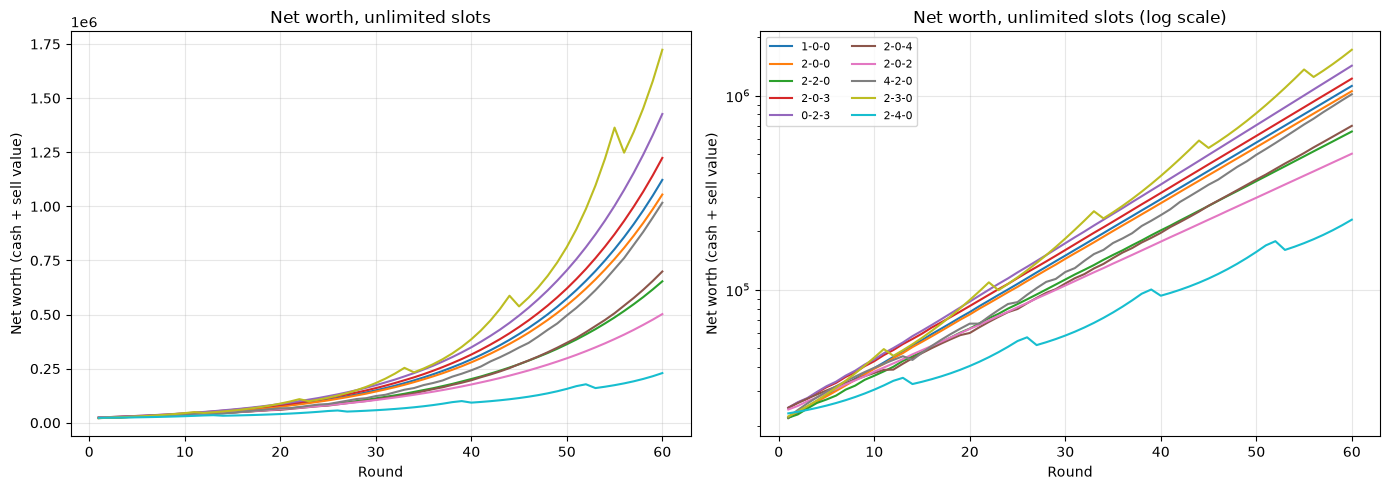

In [8]:
worth_unlimited = compare(specs, N_ROUNDS, START_CASH)
rounds = np.arange(1, N_ROUNDS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, log_scale in zip(axes, [False, True]):
    for i, name in enumerate(names):
        ax.plot(rounds, worth_unlimited[i], label=name, color=colors[name])
    if log_scale:
        ax.set_yscale("log")
    ax.set_xlabel("Round")
    ax.set_ylabel("Net worth (cash + sell value)")
    ax.set_title("Net worth, unlimited slots" + (" (log scale)" if log_scale else ""))
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

It is interesting to note that the bank towers have drops in net worth. This is due to collecting the cash from the balance and buying new banks which slows down production until they gain interest. However if we notice the plot for the 4-2-0 farm in the log scale, we can see it wiggle a bit, meaning that there are slight drops too. This is because the farm is quite expensive so we have a drop in net worth before it gains back what we lost.

Now let's compare to a finite amount of slots (which is what is to be seen practically in-game)

### Limited Slots

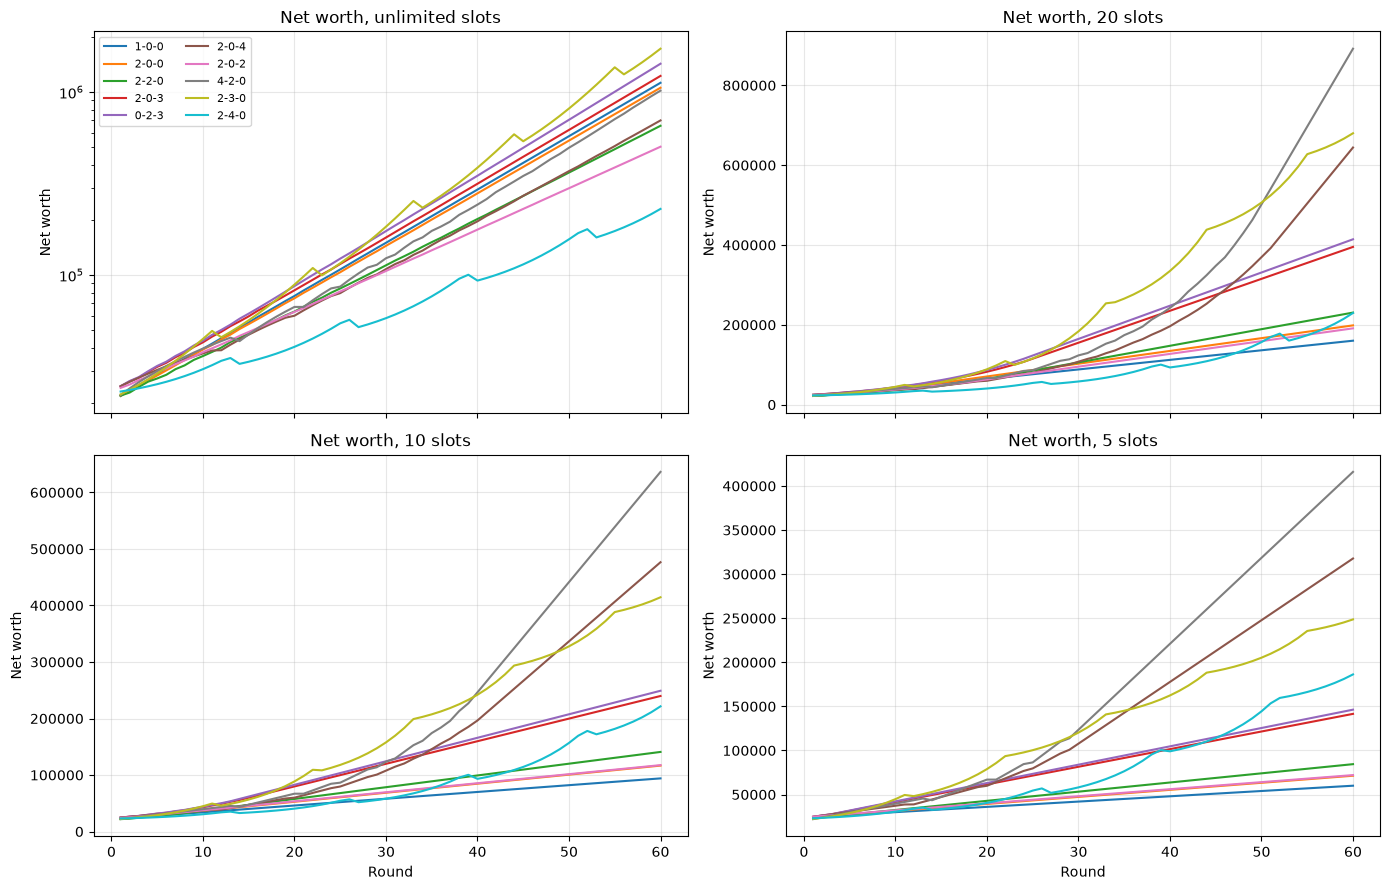

In [9]:
def cap_label(cap):
    return "unlimited slots" if cap is None else f"{cap} slots"

results = {cap: compare(specs, N_ROUNDS, START_CASH, max_slots=cap) for cap in SLOT_CAPS}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, cap in zip(axes.ravel(), SLOT_CAPS):
    for i, name in enumerate(names):
        ax.plot(rounds, results[cap][i], label=name, color=colors[name])
    ax.set_title(f"Net worth, {cap_label(cap)}")
    ax.set_ylabel("Net worth")
    if cap is None:
        ax.set_yscale("log")
for ax in axes[1]:
    ax.set_xlabel("Round")
axes[0, 0].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

The results are very interesting. In a normal game we see that the 4-2-0 dominates, in fact. Consistently behind it we have the 2-0-4 which is a bottom path "lazy" farm (since it automatically produces cash) - since it is a tier 4 it should make enough money so it makes sense that when we fill the map with them, that they'd make a reasonable amount of cash.

And of course, we cannot ignore the 2-3-0 bank tower. Purely from these graphs we can see that the more slots there are, the higher the bank's net worth is and the more it contests with the 4-2-0 farm. This is especially true when we refer to our graph with unlimited slots where the bank is a clear winner. So in other words, as the number of available slots approach infinity, the better the bank's net worth becomes after a set amount of rounds (in this simulation, 60).

But wait there is another difference in our unlimited slots graph. The 4-2-0 can't be even seen as the top contenders, it is instead the 0-2-3 bottom path farm and below it the 2-0-3 one. In the finite graphs we can see them be very close to each other and barely be a bit better than the other options, but in the unlimited one they are 2nd and 3rd place? This means that this farm reinvests into itself better as you continue getting them, similarly to banks and unlike the more expensive farms that require more money to buy another instance.

But wait (yet again!), if we think about it, in theoretically infinite amount of slots, the towers that are cheaper, are more cost-efficient than the expensive (which also produce more cash) farm towers. But we have to also consider the practicality of it. If we actually have that much starting cash, there's no reason not to go for the most expensive option, since in the long run it produces much more cash. Very interesting to think about.

Now let's look at some tables:

In [10]:
# How many farms does each build end up with when there is no limit?
pd.DataFrame({
    "tier_name": names,
    "farms_after_last_round": [simulate(s, N_ROUNDS, START_CASH).n_farms[-1] for s in specs], 
}) # Note: Keep in mind that there are 60 rounds in the simulation and we have a finite amount of cash!

,tier_name,farms_after_last_round
0,1-0-0,775
1,2-0-0,540
2,2-2-0,229
3,2-0-3,229
4,0-2-3,266
5,2-0-4,35
6,2-0-2,182
7,4-2-0,47
8,2-3-0,213
9,2-4-0,14


Here it makes sense that the more expensive a tower is, the less we will have of it compared to the cheaper options. Regardless of this, it still generates a reasonable amount of income.

In [11]:
# Which build has the highest net worth after N rounds?
horizons = [10, 20, 30, 40, 50, 60]
pd.DataFrame(
    {cap_label(cap): [names[results[cap][:, h - 1].argmax()] for h in horizons] for cap in SLOT_CAPS},
    index=pd.Index(horizons, name="rounds played"),
)

,unlimited slots,20 slots,10 slots,5 slots
rounds played,,,,
10,2-3-0,2-3-0,2-3-0,2-3-0
20,2-3-0,2-3-0,2-3-0,2-3-0
30,2-3-0,2-3-0,2-3-0,4-2-0
40,2-3-0,2-3-0,4-2-0,4-2-0
50,2-3-0,2-3-0,4-2-0,4-2-0
60,2-3-0,4-2-0,4-2-0,4-2-0


Hm, so let's analyze this. With unlimited slots, the bank wins. However the less spots you have, the more the 4-2-0 farm wins. This checks out with the bank paying back its cost much quicker than the 4-2-0 farm due to it being more efficient in general. This is also backed up by the efficiency graph we analyzed earlier.

So with all of this in mind..

## Does Efficiency Predict The Winner?
The efficiency for each farm we measured before, and the net worth simulation we discussed just now - do they have correlation?

We'll measure this using **Spearman Correlation**. It fits for this case because it evaluates whether the rankings (not raw values) of the 2 variables we have (efficiency vs net worth) move together, such as when one increases, so does the other (positive relationship). So in the graph the higher the number is, the stronger the correlation is.

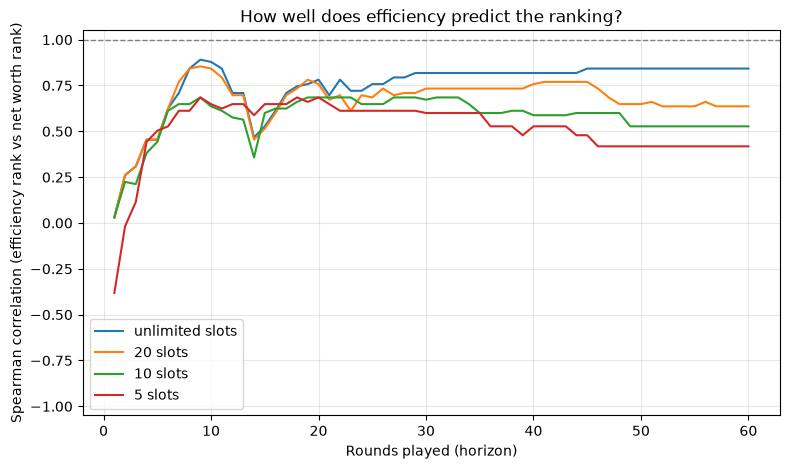

 unlimited slots: a new build takes the lead in rounds [10 12 20 23 29]
        20 slots: a new build takes the lead in rounds [10 12 20 23 28 51]
        10 slots: a new build takes the lead in rounds [10 12 19 40]
         5 slots: a new build takes the lead in rounds [ 2  9 30]


In [12]:
fig, ax = plt.subplots()
for cap in SLOT_CAPS:
    ax.plot(rounds, rank_agreement(specs, results[cap]), label=cap_label(cap))

ax.axhline(1, color="grey", linestyle="--", linewidth=1)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel("Rounds played (horizon)")
ax.set_ylabel("Spearman correlation (efficiency rank vs net worth rank)")
ax.set_title("How well does efficiency predict the ranking?")
ax.legend()
plt.show()

for cap in SLOT_CAPS:
    print(f"{cap_label(cap):>16}: a new build takes the lead in rounds {leader_changes(results[cap])}")

Let's explain what we're observing:

A leader change (the farm with the most net worth) here means that two net worth curves crossed, one overtaking the other. Consequently, this means that the best farm depends on the horizon (the span of rounds over which we're simulating). The efficiency gives a fixed best build (2-3-0), but the 2-3-0 actually leads only in 37, 28, 23 and 21 amount of rounds out of 60 (for unlimited, 20, 10 and 5 slots). Two patterns stand out here:

- With unlimited slots the lead alternates between the tier 3 bottom path farms (2-0-3, 0-2-3), which we noted above to have better net worth. This is due to the farm's 11 round cycle - when you collect and buy new banks, the net worth dips by the sell loss and later regrows.
- With limited slots the 4-2-0 farm takes the lead at round 30 (5 slots), 40 (10 slots), 51 (20 slots) and never with unlimited slots  

Let's also visualize this correlation in a table:

In [13]:
def rank_table(cap, horizon):
    eps = np.array([calculate_efficiency(s) for s in specs])
    net_worth = results[cap][:, horizon - 1]
    table = pd.DataFrame({
        "tier_name": names,
        "efficiency_rank": (-eps).argsort().argsort() + 1,   # 1 = best
        "net_worth_rank": (-net_worth).argsort().argsort() + 1,
    })
    table["difference"] = table["net_worth_rank"] - table["efficiency_rank"]
    return table.sort_values("efficiency_rank")

rank_table(5, 60)

,tier_name,efficiency_rank,net_worth_rank,difference
8,2-3-0,1,3,2
7,4-2-0,2,1,-1
4,0-2-3,3,5,2
3,2-0-3,4,6,2
0,1-0-0,5,10,5
1,2-0-0,6,9,3
5,2-0-4,7,2,-5
9,2-4-0,8,4,-4
2,2-2-0,9,7,-2
6,2-0-2,10,8,-2


The smaller the difference is, the more correlation there is. We can notice that the 4-2-0 farm leads but what's interesting is that there are a few big differences. Most notably the tier 4 farms which on paper are less efficient but make up their value with their net worth rank. Another observation is that the 1-0-0 farm which has the lowest net worth rank also having the biggest difference, from this you could argue that spending extra to buy the tier 2 upgrade is indeed better overall.

## When Should You Stop Buying Farms?
Efficiency tells us that a farm pays back itself so we should always buy it. But at the span of the rounds we're working with (the horizon) the farms are counted at the sell value, not what we paid. So a farm bought late loses us money since there isn't enough time (not enough rounds) to earn back the money we invested for it. 

So here we will see which is the best round in which we should stop buying:

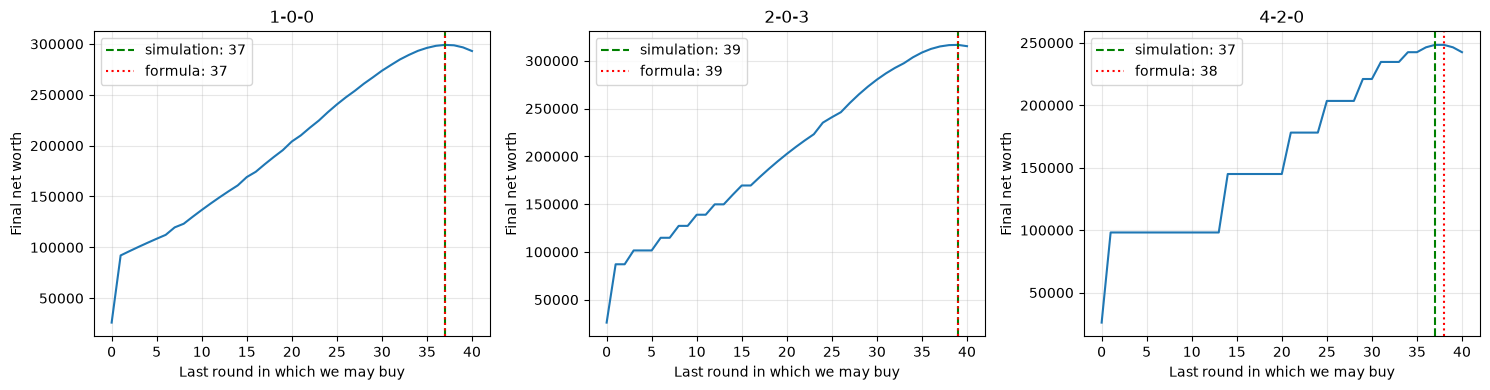

In [14]:
STOP_HORIZON = 40
flat_builds = ["1-0-0", "2-0-3", "4-2-0"]

fig, axes = plt.subplots(1, len(flat_builds), figsize=(15, 4))
for ax, name in zip(axes, flat_builds):
    spec = specs[names.index(name)]
    best_round, finals = best_stop_round(spec, STOP_HORIZON, START_CASH)

    # Buying in round r pays off when (STOP_HORIZON - r + 1) * income > (1 - sell_rate) * cost
    loss_in_rounds = (1 - spec.sell_rate) * spec.cost / spec.income
    predicted = int(np.ceil(STOP_HORIZON + 1 - loss_in_rounds)) - 1 # THIS is the formula in the plot's legend

    ax.plot(range(STOP_HORIZON + 1), finals)
    ax.axvline(best_round, color="green", linestyle="--", label=f"simulation: {best_round}")
    ax.axvline(predicted, color="red", linestyle=":", label=f"formula: {predicted}")
    ax.set_title(name)
    ax.set_xlabel("Last round in which we may buy")
    ax.set_ylabel("Final net worth")
    ax.legend()
plt.tight_layout()
plt.show()

Here I want to immediately note that the last round in which we should buy a 2-0-3 farm is just before the final one. This is due to the increased sellback rate of the bottom X-X-2 crosspath. This is where this crosspath matters and how it differs with the efficiency.

We should also note that the simulation and formula differ for the 4-2-0 farm. This is because the formula assumes that we can always afford the farm while the simulation buys the farm when we actually have the cash to do so.

And to simply explain this graph - the curve drops when we keep buying after the said round since we're losing on the net worth due to the sellback rate being less than the cost of the farm.

## In-game Verification
All of what we said is nothing until we see how it holds up in the actual game. This is the most interesting check.

First let's start with confirming the best collect every round period for the banks. The simulations say that for a 2-3-0 it's every 11 rounds, and for a 2-4-0 it's every 13.

Let's see this in-game (NOTE: I am playing in sandbox mode to simulate the rounds passing, the net worth here doesn't matter - only the income making and round simulation does):

<video width="1280" height="720" controls>
  <source src="./media/videos/banks_edited.mp4" type="video/mp4">
</video>

What I didn't add in the video is that after the last round ends, we actually end up losing cash:

Before the round ends we have accumulated 11610 of cash, with 15% interest we get $ 11610*1.15 = 13351.5 $

This also explains why the curve leading up to the last round isn't as steep as the one on the other bank.

With this out of the way, what should be tested next is the efficiency and net worth, however to properly do that, the bare minimum is doing 4 separate runs. But we can simplify that by testing our simulation where we keep buying farms when we can afford them and we test the net worth for all tower after a set number of rounds. Let's do that with the 1-0-0 over the span of 6 rounds with starting cash 3000:

<video width="1280" height="720" controls>
  <source src="./media/videos/farm_test.mp4" type="video/mp4">
</video>

Keep in mind that I know that it [produces 6 bananas](https://www.bloonswiki.com/Increased_Production_(BTD6)) every round so I know when begin the next round (conveniently enough this also avoids [end-of-round cash](https://www.bloonswiki.com/Cash))

Conveniently enough, we have code to compare what we measured in-game and what our simulation measures. And for more clarity I added more samples:

In [18]:
VALIDATION_BUILD = "1-0-0"
VALIDATION_START_CASH = 3000
measured = {1: 2724, 2: 2844, 3: 2964, 4: 3084, 5: 2928, 6: 3168, 7: 3408, 10: 4128}   


spec = specs[names.index(VALIDATION_BUILD)]
simulated = simulate(spec, max(measured), VALIDATION_START_CASH).net_worth
comparison = pd.DataFrame({
    "round": list(measured),
    "measured": list(measured.values()),
    "simulated": [simulated[r - 1] for r in measured],
})
comparison["error"] = comparison["simulated"] - comparison["measured"]
comparison["relative_error_%"] = 100 * comparison["error"] / comparison["measured"]
display(comparison.round(1))

,round,measured,simulated,error,relative_error_%
0,1,2724,2723.2,-0.8,-0.0
1,2,2844,2843.2,-0.8,-0.0
2,3,2964,2963.2,-0.8,-0.0
3,4,3084,3083.2,-0.8,-0.0
4,5,2928,2926.5,-1.5,-0.1
5,6,3168,3166.5,-1.5,-0.0
6,7,3408,3406.5,-1.5,-0.0
7,10,4128,4126.5,-1.5,-0.0


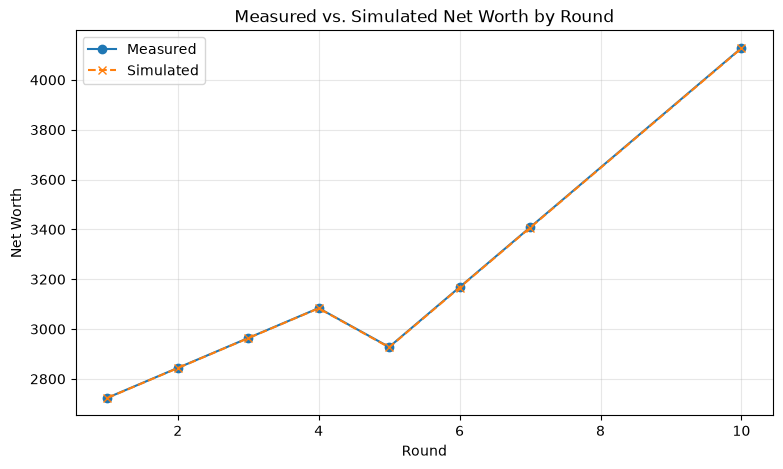

In [16]:
plt.plot(
    comparison["round"],
    comparison["measured"],
    marker="o",
    label="Measured",
    linestyle="-",
)
plt.plot(
    comparison["round"],
    comparison["simulated"],
    marker="x",
    label="Simulated",
    linestyle="--",
)

plt.xlabel("Round")
plt.ylabel("Net Worth")
plt.title("Measured vs. Simulated Net Worth by Round")
plt.legend()
plt.show()

Other than some rounding differences between the game and the simulation (which funnily enough is also seen with the bank interest rounding), the simulation is pretty accurate to the actual game. With the plot we also see that when we can buy a farm, we lose on net worth which goes back to our previous discussion about the best round to stop buying farms. If this were such a test with a 5 round horizon, then the best round to stop buying farms would be on round 4 as seen by the plot.

## Conclusion

The efficiency ($\varepsilon$, cash per round divided by total cost) predicts the ordering of the builds only partly. With unlimited farm slots the agreement between the efficiency ranking and the net worth ranking is high (Spearman $\rho$ between 0.82 and 0.84 from round 29 onwards). With limited slots it falls: after 60 rounds $\rho$ is 0.64 with 20 slots, 0.53 with 10 slots and 0.42 with 5 slots. This is useful theoretically but practically we have limited slots, so the efficiency predicting the net worth isn't of much use.

### Where the prediction fails
1. **Limited space**: With few slots, income per slot matters more than income per dollar, so expensive farms such as 2-0-4 and 4-2-0 overtake cheap ones such as 1-0-0.
2. **Large purchases**: 4-2-0 has the 2nd highest efficiency but, with unlimited slots, only the 6th highest net worth, because it costs almost the whole budget and cannot be reinvested in small steps.
3. **Banks**: Their income is delayed and arrives in lumps, so their net worth rises and dips with the collection cycle. The leading build alternates between 0-2-3 and 2-3-0 every few rounds, and no single build is best at every horizon.
4. **Sell loss and short horizons**: The efficiency ($\varepsilon$) ignores resale. A farm bought at the last (or last few) round/s loses money, which is why the last worthwhile purchase is a fixed number of rounds before the horizon.

So there is some correlation, which is fascinating.

Thank you for your time :)

## Used References
- BTD6 (Bloons Tower Defense 6) - a game by [Ninja Kiwi](https://en.wikipedia.org/wiki/Ninja_Kiwi)
- The Bloons TD 6 "[Blooncyclopedia](https://www.bloonswiki.com/Bloons_TD_6)"
- The Bloons TD 6 [Fandom Wiki](https://bloons.fandom.com/wiki/Bloons_TD_6)
- Video "[The Mathematics of Banana Farms (Bloons TD 6)](https://youtu.be/DsH0NZQsRbU?si=p_jyTLr3aTxvYLjy)" by [ALEX on Science](https://www.youtube.com/@alexonscience)